# Play around with surface temperature data from CMIP6 G1 experiments
This is 

In [69]:
import sys
import os
import inspect
from matplotlib.lines import Line2D
from glob import glob
from collections.abc import Sequence
import cartopy.crs as ccrs
import cartopy.feature as cfeature


from isca_tools.thesis.adiabat_theory import get_temp_adiabat
from isca_tools.thesis.season_annual_harmonic import get_phase_amp
from isca_tools.thesis.surface_flux_taylor_2layer import get_sensitivity_lh
from isca_tools.utils.moist_physics import sphum_sat
from isca_tools.utils.numerical import sum_complex
from isca_tools.thesis.lapse_integral_simple import get_lnb_ind, get_temp_2_layer_approx
from isca_tools.utils.xarray import wrap_with_apply_ufunc, isel_float
from isca_tools.utils.numerical import spline_deriv_nonperiodic
from isca_tools.utils.land import get_land_coords, get_ocean_coords

# REMOTE - So can access functions in isca_tools which is in home/Isca directory
# sys.path.append(os.path.join(os.environ['HOME'], 'Isca'))
# LOCAL - So can access functions in isca_tools which is in StAndrews/Isca
sys.path.append(os.environ['PWD'])
from isca_tools.utils.constants import kappa, L_v, c_p, c_p_ocean, rho_ocean, Stefan_Boltzmann, R, R_v, g, radius_earth, lapse_dry

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from isca_tools.plot import fig_resize, update_fontsize, update_linewidth, savefig, label_subplots
import isca_tools
from isca_tools.utils.load import load_namelist
from isca_tools.utils.base import mass_weighted_vertical_integral
# Use custom matplotlib style for publishing
plt.style.use('/Users/joshduffield/Documents/StAndrews/Isca/jobs/tau_sweep/aquaplanet/publish_figures/publish.mplstyle')
ax_linewidth = plt.rcParams['axes.linewidth']

from jobs.thesis_season.publish_figs.load import day_seconds, width
from jobs.thesis_season.publish_figs.xr_funcs import get_fourier_fit_xr, fourier_series_xr

In [2]:
data_dir = '/Users/joshduffield/Documents/StAndrews/Isca/jobs/nerc_srm/data/raw'
model = 'IPSL-CM6A-LR'
exp = ['piControl', 'G1']
n_exp = len(exp)
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
ds_base = []
ds = []
lat_min = 30
vars = ['ts', 'rsds', 'rsdt', 'rsus', 'rsut']
for i in range(len(exp)):
    var_data = {}
    for var in vars:
        pattern = f"{data_dir}/CMIP6/{var}/{var}_Amon_{model}_{exp[i]}_*.nc"
        files = sorted(glob(pattern))

        if not files:
            raise FileNotFoundError(f"No files found for {var}: {pattern}")

        var_data[var] = xr.open_mfdataset(
            files, decode_times=time_coder
        )[var]

    ds_use = xr.Dataset(var_data)
    ds_base.append(ds_use.where(np.abs(ds_use.lat) > lat_min).load())

    # Preserve the existing monthly surface-temperature data in ds.
    ds.append(ds_base[i].groupby("time.month").mean("time"))

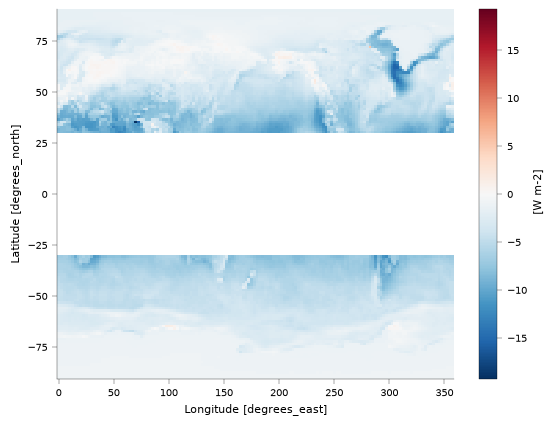

In [28]:
sw_toa_net = [ds[i]["rsdt"] - ds[i]["rsut"] for i in range(n_exp)]
(sw_toa_net[1].mean(dim='month') - sw_toa_net[0].mean(dim='month')).plot()

In [13]:
month_days = (31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31)
def fit_monthly_harmonics(
    clim: xr.Dataset,
    n_harmonics: int = 2,
    *,
    variables: Sequence[str] | None = None,
    month_days: Sequence[float] = month_days,
    day_step: float = 1.0,
    day_offset: float = 0,
    return_coefs: bool = False
) -> xr.Dataset:
    """Fit periodic curves to monthly climatologies in a dataset.

    Each fitted curve is compared with the input using its average
    over each month, not its value at the midpoint of that month.

    Args:
        clim: Dataset with a ``month`` coordinate labelled 1 through 12.
            Other dimensions, such as member, latitude, and longitude,
            are retained.
        n_harmonics: Number of sine–cosine pairs, from 0 to 6.
            Zero fits a constant. Six gives an underdetermined fit
            and uses the minimum-norm coefficient solution.
        variables: Variables to fit. By default, fit all numeric data
            variables with a ``month`` dimension.
        month_days: Lengths of January through December, in days.
            Defaults to a 365-day no-leap calendar.
        day_step: Spacing of the output grid, in days.
        day_offset: Offset of all days in unit of days i.e., 
            0.5 means the first day is 0.5 days after the start of 1 January.
        return_coefs: If True, return a second dataset containing the fitted
            coefficients, amplitudes, and phases.

    Returns:
        Dataset containing the fitted variables, with ``month`` replaced
        by ``day``. Day zero is the start of 1 January. Any series
        missing one or more monthly values is returned as all NaN.

    Raises:
        ValueError: If the settings or selected variables are invalid.
    """
    array_input = isinstance(clim, xr.DataArray)
    if array_input:
        if variables is not None:
            raise ValueError("'variables' is only supported for Dataset inputs.")

        original_name = clim.name
        array_key = "__monthly_input__"
        while array_key in clim.coords:
            array_key += "_"

        clim = clim.to_dataset(name=array_key)
        variables = [array_key]

    if not isinstance(n_harmonics, (int, np.integer)) or not 0 <= n_harmonics <= 6:
        raise ValueError("n_harmonics must be an integer from 0 to 6.")
    if not np.isfinite(day_step) or day_step <= 0:
        raise ValueError("day_step must be positive and finite.")

    days = np.asarray(month_days, dtype=float)
    if days.shape != (12,) or not np.all(np.isfinite(days) & (days > 0)):
        raise ValueError("month_days must contain 12 positive, finite lengths.")

    months = np.arange(1, 13)
    if "month" not in clim.coords or clim["month"].dims != ("month",):
        raise ValueError("Expected a one-dimensional 'month' coordinate.")

    names = list(variables) if variables is not None else [
        name for name, da in clim.data_vars.items()
        if "month" in da.dims and np.issubdtype(da.dtype, np.number)
    ]
    if not names:
        raise ValueError("No monthly variables to fit.")
    for name in names:
        if name not in clim.data_vars or "month" not in clim[name].dims:
            raise ValueError(f"{name!r} is not a data variable with a month dimension.")
        if not np.issubdtype(clim[name].dtype, np.number):
            raise ValueError(f"{name!r} must be numeric.")

    edges = np.r_[0.0, days.cumsum()]
    period = edges[-1]
    w = 2 * np.pi * np.arange(1, n_harmonics + 1) / period
    angles = edges[:, None] * w
    scale = days[:, None] * w

    # Integrate each basis function over each month, then divide by its length.
    design = np.column_stack([
        np.ones(12),
        np.diff(np.sin(angles), axis=0) / scale,
        -np.diff(np.cos(angles), axis=0) / scale,
    ])

    day = np.arange(0, period, day_step) + day_offset
    theta = day[:, None] * w
    basis = np.column_stack([
        np.ones(day.size),
        np.cos(theta),
        np.sin(theta),
    ])

    terms = (
        ["mean"]
        + [f"cos{k}" for k in range(1, n_harmonics + 1)]
        + [f"sin{k}" for k in range(1, n_harmonics + 1)]
    )

    projection = xr.DataArray(
        np.linalg.pinv(design),
        dims=("coef", "month"),
        coords={"coef": terms, "month": months},
    )
    evaluation = xr.DataArray(
        basis,
        dims=("day", "coef"),
        coords={"day": day, "coef": terms},
    )
    harmonics = np.arange(1, n_harmonics + 1)

    result = xr.Dataset(attrs={**clim.attrs, "n_harmonics": int(n_harmonics)})
    diagnostics = xr.Dataset(
        attrs={"period_days": float(period), "phase_origin": "Start of 1 January"}
    )

    for name in names:
        monthly = clim[name].reindex(month=months)
        complete = np.isfinite(monthly).all("month")
        coef = xr.dot(projection, monthly.where(complete, 0), dim="month")
        coef = coef.where(complete)

        fitted = xr.dot(evaluation, coef, dim="coef")
        result[name] = fitted.transpose(
            *("day" if dim == "month" else dim for dim in monthly.dims)
        )
        result[name].attrs = monthly.attrs.copy()

        if return_coefs:
            cos_coef = (
                coef.isel(coef=slice(1, 1 + n_harmonics))
                .rename(coef="harmonic")
                .assign_coords(harmonic=harmonics)
            )
            sin_coef = (
                coef.isel(coef=slice(1 + n_harmonics, None))
                .rename(coef="harmonic")
                .assign_coords(harmonic=harmonics)
            )

            # Amp and phase coefs so amp coef same sign as cos coef, phase in [-pi/2, pi/2] range
            magnitude = np.hypot(cos_coef, sin_coef)
            sign = xr.where(cos_coef < 0, -1.0, 1.0)
            amplitude = sign * magnitude
            phase = np.arctan2(sign * sin_coef, sign * cos_coef).where(magnitude > 0)

            prefix = "" if array_input else f"{name}_"
            diagnostics[f"{prefix}mean"] = coef.sel(coef="mean", drop=True)
            diagnostics[f"{prefix}cos_coef"] = cos_coef
            diagnostics[f"{prefix}sin_coef"] = sin_coef
            diagnostics[f"{prefix}amplitude"] = amplitude
            diagnostics[f"{prefix}phase"] = phase.assign_attrs(units="rad")

    result["day"].attrs["long_name"] = "Days since start of climatological year"

    if array_input:
        fit = result[array_key].rename(original_name)
        fit.attrs["n_harmonics"] = int(n_harmonics)
    else:
        fit = result

    return (fit, diagnostics) if return_coefs else fit


var = fit_monthly_harmonics(ds[0], n_harmonics=1)
var2 = fit_monthly_harmonics(ds[0], n_harmonics=5)

### Sanity check that Fourier fitting works
Here, we see that the fit lines up with the monthly means, as a sanity check that the Fourier fit is a good representation of the monthly mean data.

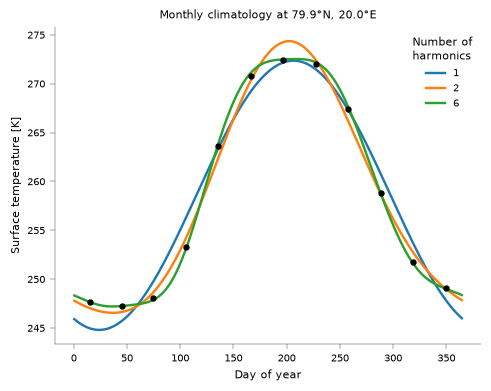

In [18]:
edges = np.r_[0, np.array(month_days).cumsum()]
midpoints = (edges[:-1] + edges[1:]) / 2

lat_plot = 80
lon_plot = 20
var = ds[0].ts.sel(lat=lat_plot, lon=lon_plot, method="nearest")

fig, ax = plt.subplots(1, 1)
fig_resize(fig, width['two_col'])
ax.scatter(midpoints, var, marker='.', s=50, color='k', zorder=50)
for n_harmonics in [1, 2, 6]:
    var_fit = fit_monthly_harmonics(var, n_harmonics=n_harmonics, day_offset=0.5)
    ax.plot(var_fit.day, var_fit, label=f"{n_harmonics}")
update_linewidth(fig)
ax.legend(title='Number of\nharmonics')
ax.set_xlabel("Day of year")
ax.set_ylabel('Surface temperature [K]')
ax.set_title(f"Monthly climatology at {var.lat:.1f}°N, {var.lon:.1f}°E")
plt.show()

### How many harmonics required?
Below I compute the number of harmonics required for the mean absolute error in the Fourier fit, normalised by the annual harmonic amplitude be less than 10%. We see that this is at most 2 for basically all regions for surface temperature, meaning 2 harmonics seems to be a reasonable approximation.

In [15]:
def sample_month_midpoints(
    fit: xr.DataArray | xr.Dataset,
    *,
    month_days: Sequence[float] = month_days,
) -> xr.DataArray | xr.Dataset:
    """Sample a fitted seasonal cycle at calendar-month midpoints.

    Args:
        fit: Fitted curve with a ``day`` coordinate measured in days
            from the start of 1 January (day zero).
        month_days: Lengths of January through December. Use the same
            values as in the original fit.

    Returns:
        The same xarray type as the input, with 12 samples along
        ``month`` in place of ``day``. The sampled day values are
        retained as an auxiliary coordinate.

    Raises:
        ValueError: If the month lengths are invalid or the day grid
            does not cover all 12 midpoints.
    """
    days = np.asarray(month_days, dtype=float)
    if days.shape != (12,) or not np.all(np.isfinite(days) & (days > 0)):
        raise ValueError("month_days must contain 12 positive, finite lengths.")
    if "day" not in fit.coords or fit["day"].dims != ("day",):
        raise ValueError("Expected a one-dimensional 'day' coordinate.")

    edges = np.r_[0.0, days.cumsum()]
    midpoints = (edges[:-1] + edges[1:]) / 2

    if not (
        fit["day"].min().item() <= midpoints[0]
        and fit["day"].max().item() >= midpoints[-1]
    ):
        raise ValueError("The fitted day grid must cover all 12 month midpoints.")

    target = xr.DataArray(
        midpoints,
        dims="month",
        coords={"month": np.arange(1, 13)},
    )
    return fit.interp(day=target)

In [31]:
def get_error(
    ds: xr.Dataset | xr.DataArray,
    n_harmonics: int,
    *,
    month_days: Sequence[float] = month_days,
) -> xr.Dataset | xr.DataArray:
    """Compute midpoint-sampled error as a percentage of annual amplitude.

    For each fitted variable, compute the mean absolute difference between
    the fitted curve at the 12 month midpoints and the input monthly means.
    Normalize by the magnitude of the annual harmonic from a separate
    one-harmonic fit. Each month contributes equally to the error.

    Args:
        ds: Monthly climatology with a ``month`` coordinate labelled 1
            through 12. For a Dataset, only variables fitted by
            ``fit_monthly_harmonics`` are included.
        n_harmonics: Number of harmonics in the fit being evaluated.
        month_days: Lengths of January through December, in days. Defaults
            to a 365-day no-leap calendar. Use ``[30] * 12`` for a
            360-day calendar.

    Returns:
        Normalized error in percent, with the same xarray type as ``ds``
        and with the ``month`` dimension removed. Locations with missing
        monthly data or zero annual amplitude return NaN.
    """
    annual_fit, coefs = fit_monthly_harmonics(
        ds, n_harmonics=1, month_days=month_days, return_coefs=True
    )

    if isinstance(ds, xr.DataArray):
        norm_factor = np.abs(coefs["amplitude"].sel(harmonic=1, drop=True))
        name = ds.name
    else:
        names = list(annual_fit.data_vars)
        norm_factor = xr.Dataset({
            name: np.abs(
                coefs[f"{name}_amplitude"].sel(harmonic=1, drop=True)
            )
            for name in names
        })
        ds = ds[names]

    fit = annual_fit if n_harmonics == 1 else fit_monthly_harmonics(
        ds, n_harmonics=n_harmonics, month_days=month_days
    )
    sampled = sample_month_midpoints(fit, month_days=month_days)

    mae = np.abs(sampled - ds).mean("month", skipna=False)
    error = 100 * mae / norm_factor.where(norm_factor > 0)

    if isinstance(error, xr.DataArray):
        return error.rename(name).assign_attrs(units="%")

    return error.assign({
        var: error[var].assign_attrs(units="%") for var in error.data_vars
    })

In [106]:
var = "ts"
error_thresh = 10.0  # get_error returns percentages

required_by_exp = []

for i in range(n_exp):
    required = None

    for n_harmonics in range(1, 5):
        error = get_error(ds[i][var], n_harmonics=n_harmonics)

        if required is None:
            required = xr.full_like(error, np.nan, dtype=float)

        # Fill only locations that haven't met the threshold yet.
        required = xr.where(
            required.isnull() & (error < error_thresh),
            n_harmonics,
            required,
        )

    required_by_exp.append(required)

n_required = xr.concat(
    required_by_exp,
    dim=xr.IndexVariable("experiment", np.arange(n_exp)),
).rename("n_harmonics_required")
n_required.attrs['variable'] = var

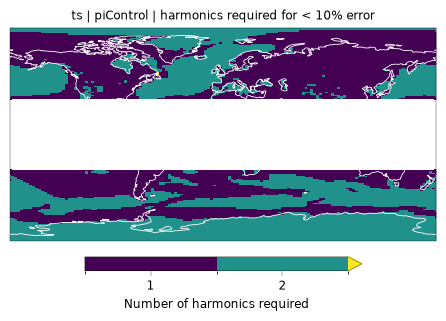

In [109]:
exp_ind_plot = 0
# Harmonic counts tested. Use np.arange(0, 7) if you also tested a constant fit.
counts = np.arange(1, 3)
levels = np.r_[counts - 0.5, counts[-1] + 0.5]

fig, ax = plt.subplots(
    subplot_kw={"projection": ccrs.PlateCarree()},
)
fig_resize(fig, width['two_col'])
ax.set_global()
ax.set_facecolor("white")
# ax.add_feature(cfeature.LAND, facecolor="lightgrey", zorder=0)

n_required[exp_ind_plot].plot.pcolormesh(
    ax=ax,
    x="lon",
    y="lat",
    transform=ccrs.PlateCarree(),
    cmap="viridis",
    levels=levels,
    zorder=1,
    cbar_kwargs={
        "label": "Number of harmonics required",
        "ticks": counts,
        "orientation": "horizontal",
        "pad": 0.05,
        "shrink": 0.65,
    },
)

ax.coastlines(resolution="110m", linewidth=0.6, color="w", zorder=2)
ax.set_title(f"{n_required.attrs['variable']} | {exp[exp_ind_plot]} | harmonics required for < {error_thresh:.0f}% error")
update_fontsize(fig, 5)
plt.show()

### Annual harmonic

In [111]:
def get_harmonic_extrema(
    clim: xr.Dataset | xr.DataArray,
    n_harmonics: int = 2,
    **fit_kwargs,
) -> xr.Dataset:
    """Summarize the extrema and annual mean of fitted seasonal cycles.

    Args:
        clim: Monthly climatology with a ``month`` coordinate labelled
            1 through 12. Can be a Dataset or DataArray.
        n_harmonics: Number of harmonics used in the fit.
        **fit_kwargs: Options passed to ``fit_monthly_harmonics``, such
            as ``month_days``, ``day_step``, and, for a Dataset,
            ``variables``. Coefficients are always requested internally.

    Returns:
        Dataset with ``day_min``, ``day_max``, ``value_min``, ``value_max``,
        and ``mean`` for each fitted variable. Dataset inputs prefix these
        names with the variable name. Other dimensions, such as latitude,
        longitude, and ensemble member, are retained.

        Days are measured from the start of 1 January. Extrema are found
        on the fitted day grid; ties use the first day. All-missing curves
        return NaN. The mean is the fitted Fourier constant term.
    """
    fit_kwargs = {**fit_kwargs, "return_coefs": True}
    fit, coefs = fit_monthly_harmonics(
        clim, n_harmonics=n_harmonics, **fit_kwargs
    )

    curves = (
        [("", fit)]
        if isinstance(fit, xr.DataArray)
        else [(f"{name}_", curve) for name, curve in fit.data_vars.items()]
    )

    stats = {}
    for prefix, curve in curves:
        valid = curve.notnull().any("day")

        stats[f"{prefix}day_min"] = (
            curve.fillna(np.inf).idxmin("day").where(valid)
        )
        stats[f"{prefix}day_max"] = (
            curve.fillna(-np.inf).idxmax("day").where(valid)
        )
        stats[f"{prefix}value_min"] = curve.min("day", skipna=True)
        stats[f"{prefix}value_max"] = curve.max("day", skipna=True)
        stats[f"{prefix}mean"] = coefs[f"{prefix}mean"]

        for stat in ("day_min", "day_max"):
            stats[f"{prefix}{stat}"].attrs.update(
                units="days",
                long_name=f"{stat} measured from the start of 1 January",
            )

        if "units" in curve.attrs:
            for stat in ("value_min", "value_max", "mean"):
                stats[f"{prefix}{stat}"].attrs["units"] = curve.attrs["units"]

    return xr.Dataset(stats, attrs=dict(coefs.attrs))

In [166]:
n_days_year = int(np.sum(month_days))
def get_lag(time_var, time_ref, period=n_days_year):
    """Compute the lag of a time variable relative to a reference.

    Args:
        time_var: Time variable with a ``day`` coordinate measured in
            days from the start of 1 January (day zero).
        time_ref: Reference time variable with the same ``day``
            coordinate. Can be a scalar or have other dimensions.
        period: Period of the cycle, in days. Defaults to 365.

    Returns:
        Lag in days, with the same dimensions as ``time_var`` and
        ``time_ref``. The lag is positive if ``time_var`` occurs after
        ``time_ref`` and is wrapped to the range [-period/2, period/2].
    """
    delta = time_var - time_ref
    lag = ((delta + period / 2) % period - period / 2).rename("lag")
    return lag

In [ ]:
harmonics_use = [1, 2, 6]

extrema_info = xr.concat(
    [
        xr.concat(
            [
                get_harmonic_extrema(ds[i], n_harmonics=j)
                for j in harmonics_use
            ],
            dim=xr.IndexVariable("harmonic", harmonics_use),
            join="exact",
        )
        for i in range(n_exp)
    ],
    dim=xr.IndexVariable("exp", exp),
    join="exact",
)

In [227]:
def get_amplitude(var, method: str = 'max', extrema: xr.Dataset=extrema_info):
    return np.abs(extrema[f'{var}_value_{method}'] - extrema[f'{var}_mean'])

lag = {}
gain = {}
for method in ['max', 'min']:
    lag[method] = get_lag(extrema_info[f'ts_day_{method}'].sel(harmonic=1), extrema_info[f'rsdt_day_{method}'].sel(harmonic=1))
    gain[method] = get_amplitude('ts', method).sel(harmonic=1) / get_amplitude('rsdt', method).sel(harmonic=1)
if np.abs(lag['max']-lag['min']).max() > 2:
    # Sanity check that annual harmonic lag is same if based on max or min within a tolerance of 2 days
    raise ValueError(f"Maximum lag difference: {np.abs(lag['max']-lag['min']).max():.0f} days")
if np.abs(gain['max']-gain['min']).max() > 0.01*np.abs(gain['max']).mean():
    # Sanity check that annual harmonic lag is same if based on max or min within a tolerance of 2 days
    raise ValueError(f"Maximum gain difference: {np.abs(gain['max']-gain['min']).max():.0f} K/(W/m^2)")
lag = lag['max']
gain = gain['max']

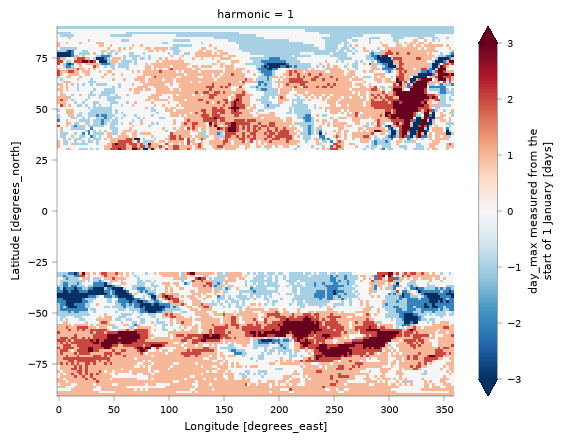

In [228]:
(lag.isel(exp=1)-lag.isel(exp=0)).plot(robust=True)

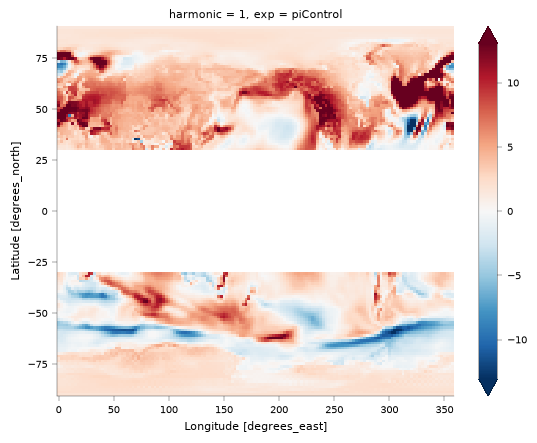

In [231]:
((gain.isel(exp=1)-gain.isel(exp=0))/gain.isel(exp=0)*100).plot(robust=True)

In [178]:
extrema_info['piControl'][1]

<xarray.Dataset> Size: 4MB
Dimensions:         (lat: 143, lon: 144)
Coordinates:
  * lat             (lat) float32 572B -90.0 -88.73 -87.46 ... 87.46 88.73 90.0
  * lon             (lon) float32 576B 0.0 2.5 5.0 7.5 ... 352.5 355.0 357.5
Data variables: (12/25)
    ts_day_min      (lat, lon) float64 165kB 182.0 182.0 182.0 ... 26.0 26.0
    ts_day_max      (lat, lon) float64 165kB 0.0 0.0 0.0 ... 208.0 208.0 208.0
    ts_value_min    (lat, lon) float64 165kB 201.2 201.2 201.2 ... 236.0 236.0
    ts_value_max    (lat, lon) float64 165kB 238.2 238.2 238.2 ... 272.3 272.3
    ts_mean         (lat, lon) float64 165kB 219.7 219.7 219.7 ... 254.1 254.1
    rsds_day_min    (lat, lon) float64 165kB 172.0 172.0 172.0 ... 349.0 349.0
    ...              ...
    rsus_mean       (lat, lon) float64 165kB 110.9 110.9 110.9 ... 74.76 74.76
    rsut_day_min    (lat, lon) float64 165kB 172.0 172.0 172.0 ... 351.0 351.0
    rsut_day_max    (lat, lon) float64 165kB 355.0 355.0 355.0 ... 169.0 169.0
    rsut_value_min  (lat, lon) float64 165kB -72.12 -72.12 ... -58.54 -58.54
    rsut_value_max  (lat, lon) float64 165kB 318.5 318.5 318.5 ... 276.1 276.1
    rsut_mean       (lat, lon) float64 165kB 123.2 123.2 123.2 ... 108.8 108.8
Attributes:
    period_days:   365.0
    phase_origin:  Start of 1 January

In [ ]:
extrema_info = get_harmonic_extrema(ds[0], n_harmonics=1)
lag_max = get_lag(var['ts_day_max'], var['rsdt_day_max'])
lag_min = get_lag(var['ts_day_min'], var['rsdt_day_min'])

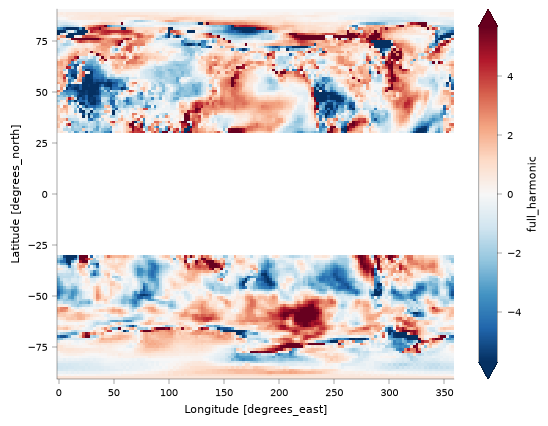

In [16]:
lag_diff.full_harmonic.plot(robust=True)

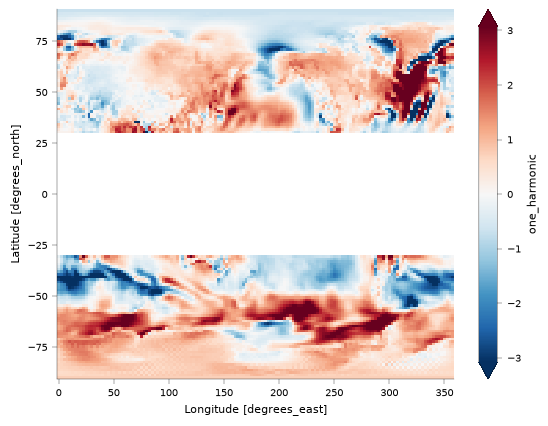

In [18]:
lag_diff.one_harmonic.plot(robust=True)

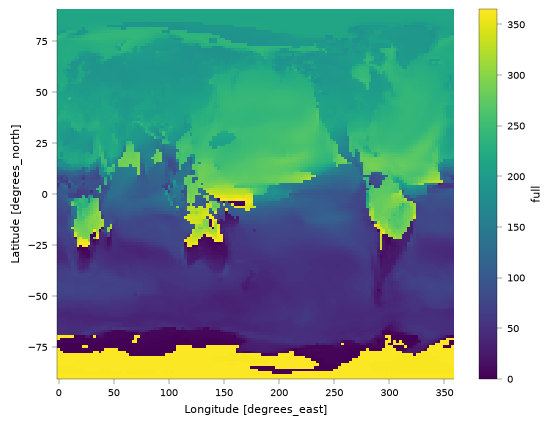

In [ ]:
temp_peak[1].full.plot()

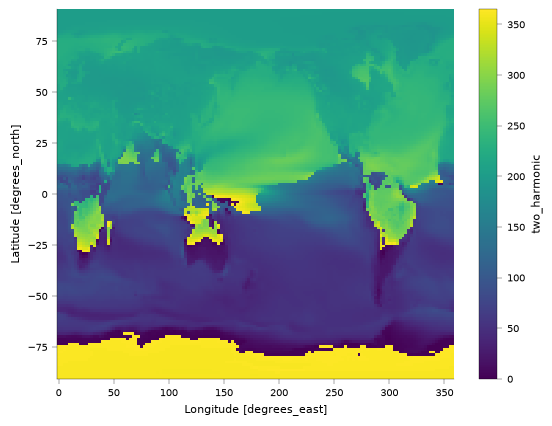

In [ ]:
temp_peak.two_harmonic.plot()

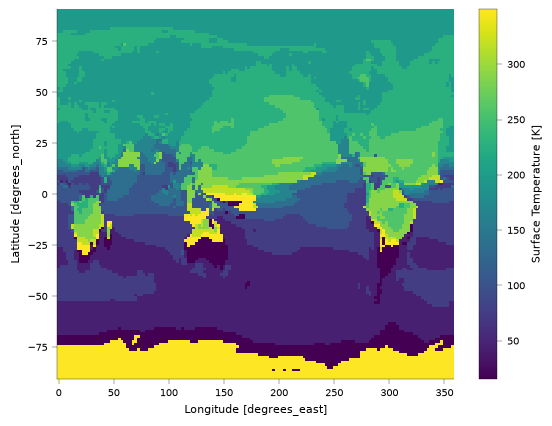

In [ ]:
temp_peak.monthly.plot()

In [ ]:
ds[0]

<xarray.DataArray 'ts' (month: 12, lat: 143, lon: 144)> Size: 988kB
array([[[243.47104, 243.47104, 243.47104, ..., 243.47104, 243.47104,
         243.47104],
        [244.94684, 244.88242, 244.80385, ..., 245.1575 , 245.08157,
         245.03934],
        [245.3965 , 245.26782, 245.13637, ..., 245.77151, 245.64859,
         245.54085],
        ...,
        [241.90263, 241.99004, 242.03503, ..., 241.68268, 241.81302,
         241.8769 ],
        [241.55038, 241.58984, 241.61409, ..., 241.47527, 241.47388,
         241.48189],
        [239.98192, 239.98192, 239.98192, ..., 239.98192, 239.98192,
         239.98192]],

       [[231.55223, 231.55223, 231.55223, ..., 231.55223, 231.55223,
         231.55223],
        [233.61034, 233.52351, 233.42949, ..., 233.84573, 233.75851,
         233.71535],
        [234.19348, 234.02808, 233.85233, ..., 234.7075 , 234.54242,
         234.39441],
...
        [248.0819 , 248.15688, 248.20024, ..., 247.88321, 247.9899 ,
         248.05333],
        [247.98785, 248.025  , 248.04816, ..., 247.91397, 247.91377,
         247.92307],
        [246.53952, 246.53952, 246.53952, ..., 246.53952, 246.53952,
         246.53952]],

       [[244.47238, 244.47238, 244.47238, ..., 244.47238, 244.47238,
         244.47238],
        [245.81432, 245.7535 , 245.67567, ..., 246.02834, 245.94823,
         245.9066 ],
        [246.22766, 246.10155, 245.97183, ..., 246.5972 , 246.47641,
         246.36763],
        ...,
        [244.0722 , 244.1542 , 244.1979 , ..., 243.86974, 243.98607,
         244.04594],
        [243.84592, 243.88745, 243.91362, ..., 243.7685 , 243.76833,
         243.77773],
        [242.347  , 242.347  , 242.347  , ..., 242.347  , 242.347  ,
         242.347  ]]], shape=(12, 143, 144), dtype=float32)
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat      (lat) float32 572B -90.0 -88.73 -87.46 -86.2 ... 87.46 88.73 90.0
  * lon      (lon) float32 576B 0.0 2.5 5.0 7.5 10.0 ... 350.0 352.5 355.0 357.5
Attributes:
    long_name:           Surface Temperature
    units:               K
    online_operation:    average
    cell_methods:        area: time: mean
    interval_operation:  900 s
    interval_write:      1 month
    standard_name:       surface_temperature
    description:         Surface temperature (skin for open ocean)
    history:             none
    cell_measures:       area: areacella

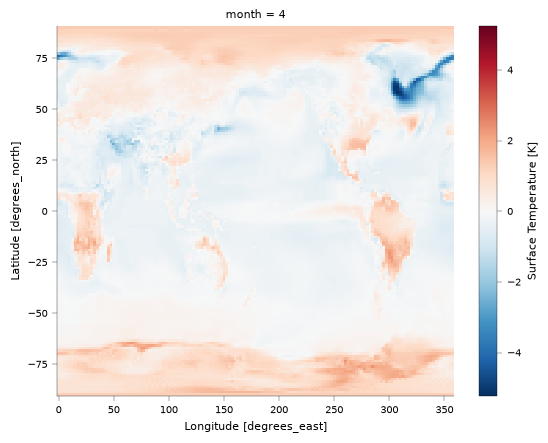

In [ ]:
(ds[1]-ds[0]).sel(month=4).plot()

In [ ]:
ds_base[1].time

<xarray.DataArray 'time' (time: 1200)> Size: 10kB
array([cftime.DatetimeGregorian(1850, 1, 16, 12, 0, 0, 0, has_year_zero=False),
       cftime.DatetimeGregorian(1850, 2, 15, 0, 0, 0, 0, has_year_zero=False),
       cftime.DatetimeGregorian(1850, 3, 16, 12, 0, 0, 0, has_year_zero=False),
       ...,
       cftime.DatetimeGregorian(1949, 10, 16, 12, 0, 0, 0, has_year_zero=False),
       cftime.DatetimeGregorian(1949, 11, 16, 0, 0, 0, 0, has_year_zero=False),
       cftime.DatetimeGregorian(1949, 12, 16, 12, 0, 0, 0, has_year_zero=False)],
      shape=(1200,), dtype=object)
Coordinates:
  * time     (time) object 10kB 1850-01-16 12:00:00 ... 1949-12-16 12:00:00
Attributes:
    axis:           T
    standard_name:  time
    long_name:      Time axis
    time_origin:    1850-01-01 00:00:00
    bounds:         time_bounds